In [1]:
  from pathlib import Path
import shutil
from sklearn.model_selection import train_test_split

# Dossiers source
POS_DIR = Path("./dataset/perruche")
NEG_DIR = Path("./dataset/pas_perruche")

# Dossier de sortie
OUT_DIR = Path("./dataset_split")

# Ratios
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

SEED = 42
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp"}

def get_images(folder):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS]

def split_files(files):
    train, temp = train_test_split(
        files,
        train_size=TRAIN_RATIO,
        random_state=SEED,
        shuffle=True
    )

    val_ratio_adjusted = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

    val, test = train_test_split(
        temp,
        train_size=val_ratio_adjusted,
        random_state=SEED,
        shuffle=True
    )

    return train, val, test

def copy_files(files, split_name, class_name):
    target_dir = OUT_DIR / split_name / class_name
    target_dir.mkdir(parents=True, exist_ok=True)

    for file in files:
        shutil.copy2(file, target_dir / file.name)

classes = {
    "perruche": POS_DIR,
    "pas_perruche": NEG_DIR
}

for class_name, folder in classes.items():
    files = get_images(folder)

    train_files, val_files, test_files = split_files(files)

    copy_files(train_files, "train", class_name)
    copy_files(val_files, "val", class_name)
    copy_files(test_files, "test", class_name)

    print(f"{class_name}:")
    print(f"  train: {len(train_files)}")
    print(f"  val:   {len(val_files)}")
    print(f"  test:  {len(test_files)}")

print("Dataset prêt.")

perruche:
  train: 2202
  val:   472
  test:  473
pas_perruche:
  train: 1514
  val:   325
  test:  325
Dataset prêt.


In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path

# ==========================
# PARAMÈTRES
# ==========================

# Point to the directory created by the data splitting script
DATASET_SPLIT_PATH = "dataset_split"

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
SEED = 42

# ==========================
# CHARGEMENT DES DATASETS SPLITTÉS
# ==========================

# Load training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "train",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Load validation dataset
val_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "val",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle validation data
)

# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "test",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle test data
)

# Affichage des classes détectées (assuming all datasets have the same classes)
print("Classes :", train_dataset.class_names)

# ==========================
# OPTIMISATION DES PERFORMANCES
# ==========================

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

# ==========================
# VÉRIFICATION
# ==========================

print("\nDatasets prêts !")
print(f"Train batches : {len(train_dataset)}")
print(f"Validation batches : {len(val_dataset)}")
print(f"Test batches : {len(test_dataset)}")


Found 3716 files belonging to 2 classes.
Found 797 files belonging to 2 classes.
Found 798 files belonging to 2 classes.
Classes : ['pas_perruche', 'perruche']

Datasets prêts !
Train batches : 117
Validation batches : 25
Test batches : 25


In [3]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal", input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20
)

Epoch 1/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9537 - loss: 0.1217 - val_accuracy: 0.9661 - val_loss: 0.1169
Epoch 2/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.9505 - loss: 0.1283 - val_accuracy: 0.9661 - val_loss: 0.0955
Epoch 3/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.9543 - loss: 0.1197 - val_accuracy: 0.9511 - val_loss: 0.1368
Epoch 4/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9505 - loss: 0.1218 - val_accuracy: 0.9511 - val_loss: 0.1419
Epoch 5/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 139s 1s/step - accuracy: 0.9491 - loss: 0.1290 - val_accuracy: 0.9598 - val_loss: 0.1173
Epoch 6/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.9524 - loss: 0.1128 - val_accuracy: 0.9486 - val_loss: 0.1247
Epoch 7/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.9545 - loss: 0.1136 - val_accuracy: 0.9523 - val_loss: 0.1498
Epoch 8/20
117/117 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9575 - loss: 0.1093 - val_accu

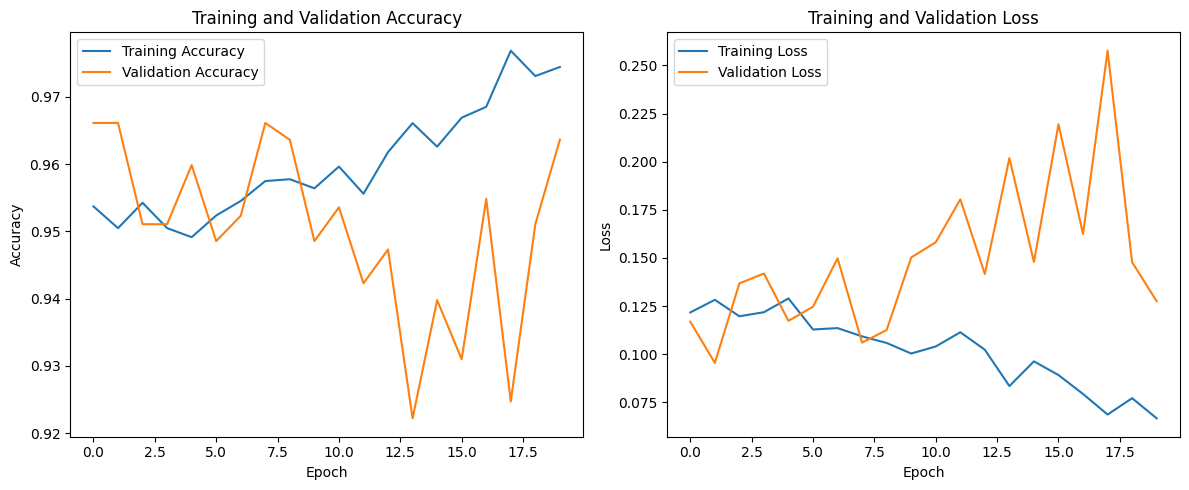

25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 244ms/step - accuracy: 0.9424 - loss: 0.2175
Accuracy test : 0.9424
Loss test : 0.2175


In [6]:
import matplotlib.pyplot as plt

# Plot training history
hist = history.history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(hist['accuracy'], label='Training Accuracy')
plt.plot(hist['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist['loss'], label='Training Loss')
plt.plot(hist['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate on test set
loss, accuracy = model.evaluate(test_dataset)

print(f"Accuracy test : {accuracy:.4f}")
print(f"Loss test : {loss:.4f}")


In [8]:
import tensorflow as tf

# Save the model in SavedModel format
model_path = "./my_bird_model"
model.export(model_path)
print(f"Model saved to: {model_path}")

# Convert the Keras model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_saved_model(model_path)
tflite_model = converter.convert()

# Save the TFLite model to a file
tflite_model_path = "./my_bird_model.tflite"
with open(tflite_model_path, "wb") as f:
    f.write(tflite_model)

print(f"TensorFlow Lite model saved to: {tflite_model_path}")

Saved artifact at './my_bird_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  135251560796176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875738064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875738640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875739792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875740560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875741520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875739984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875741712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875742480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135248875744208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1352488757426

ConverterError: Could not translate MLIR to FlatBuffer.<unknown>:0: error: loc(callsite(fused["StatelessRandomGetKeyCounter:", "sequential_1_1/sequential_1/random_flip_1/stateless_random_uniform/StatelessRandomGetKeyCounter@__inference___call___27451"] at callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper___call___27514"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]))): 'tf.StatelessRandomGetKeyCounter' op is neither a custom op nor a flex op
<unknown>:0: note: loc(callsite(fused["StatefulPartitionedCall:", "StatefulPartitionedCall@__inference_signature_wrapper___call___27514"] at fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"])): called from
<unknown>:0: note: loc(fused["StatefulPartitionedCall:", "StatefulPartitionedCall_1"]): called from
<unknown>:0: note: loc(callsite(fused["StatelessRandomGetKeyCounter:", "sequential_1_1/sequential_1/random_flip_1/stateless_random_uniform/StatelessRandomGetKeyCounte

In [9]:
import shutil

shutil.make_archive("saved_model", "zip", "my_bird_model")

'/content/saved_model.zip'

Once you have the `my_bird_model.tflite` file, you can upload it to your Edge Impulse project. Usually, this is done through the 'Create deployment' section, or by importing a custom trained model.